In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [4]:
data = pd.read_csv('Dataset/Dataset.csv')

In [88]:
data

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9546,5915730,Naml۱ Gurme,208,��stanbul,"Kemanke�� Karamustafa Pa��a Mahallesi, R۱ht۱m ...",Karak�_y,"Karak�_y, ��stanbul",28.977392,41.022793,Turkish,...,Turkish Lira(TL),No,No,No,No,3,4.1,Green,Very Good,788
9547,5908749,Ceviz A��ac۱,208,��stanbul,"Ko��uyolu Mahallesi, Muhittin ��st�_nda�� Cadd...",Ko��uyolu,"Ko��uyolu, ��stanbul",29.041297,41.009847,"World Cuisine, Patisserie, Cafe",...,Turkish Lira(TL),No,No,No,No,3,4.2,Green,Very Good,1034
9548,5915807,Huqqa,208,��stanbul,"Kuru�_e��me Mahallesi, Muallim Naci Caddesi, N...",Kuru�_e��me,"Kuru�_e��me, ��stanbul",29.034640,41.055817,"Italian, World Cuisine",...,Turkish Lira(TL),No,No,No,No,4,3.7,Yellow,Good,661
9549,5916112,A���k Kahve,208,��stanbul,"Kuru�_e��me Mahallesi, Muallim Naci Caddesi, N...",Kuru�_e��me,"Kuru�_e��me, ��stanbul",29.036019,41.057979,Restaurant Cafe,...,Turkish Lira(TL),No,No,No,No,4,4.0,Green,Very Good,901


In [89]:
data.shape

(9551, 21)

In [90]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [91]:
data.describe(include='all')

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
count,9.551000e+03,9551,9551.000000,9551,9551,9551,9551,9551.000000,9551.000000,9542,...,9551,9551,9551,9551,9551,9551.000000,9551.000000,9551,9551,9551.000000
unique,NaN,7446,NaN,141,8918,1208,1265,NaN,NaN,1825,...,12,2,2,2,1,NaN,NaN,6,6,NaN
top,NaN,Cafe Coffee Day,NaN,New Delhi,"Sector 41, Noida",Connaught Place,"Connaught Place, New Delhi",NaN,NaN,North Indian,...,Indian Rupees(Rs.),No,No,No,No,NaN,NaN,Orange,Average,NaN
freq,NaN,83,NaN,5473,11,122,122,NaN,NaN,936,...,8652,8393,7100,9517,9551,NaN,NaN,3737,3737,NaN
mean,9.051128e+06,NaN,18.365616,NaN,NaN,NaN,NaN,64.126574,25.854381,NaN,...,NaN,NaN,NaN,NaN,NaN,1.804837,2.666370,NaN,NaN,156.909748
std,8.791521e+06,NaN,56.750546,NaN,NaN,NaN,NaN,41.467058,11.007935,NaN,...,NaN,NaN,NaN,NaN,NaN,0.905609,1.516378,NaN,NaN,430.169145
min,5.300000e+01,NaN,1.000000,NaN,NaN,NaN,NaN,-157.948486,-41.330428,NaN,...,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,NaN,0.000000
25%,3.019625e+05,NaN,1.000000,NaN,NaN,NaN,NaN,77.081343,28.478713,NaN,...,NaN,NaN,NaN,NaN,NaN,1.000000,2.500000,NaN,NaN,5.000000
50%,6.004089e+06,NaN,1.000000,NaN,NaN,NaN,NaN,77.191964,28.570469,NaN,...,NaN,NaN,NaN,NaN,NaN,2.000000,3.200000,NaN,NaN,31.000000
75%,1.835229e+07,NaN,1.000000,NaN,NaN,NaN,NaN,77.282006,28.642758,NaN,...,NaN,NaN,NaN,NaN,NaN,2.000000,3.700000,NaN,NaN,131.000000


In [92]:
data.isna().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [93]:
data.duplicated().sum()

np.int64(0)

In [94]:
data.head(2)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591


In [95]:
data.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

In [96]:
print(data['Has Table booking'].value_counts())
print(data['Has Online delivery'].value_counts())
print(data['Is delivering now'].value_counts())

Has Table booking
No     8393
Yes    1158
Name: count, dtype: int64
Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64
Is delivering now
No     9517
Yes      34
Name: count, dtype: int64


In [97]:
rating_data = data[['Cuisines', 'Average Cost for two', 'Has Table booking',
       'Has Online delivery', 'Price range', 'Aggregate rating', 'Votes']]

In [98]:
rating_data.head()

,Cuisines,Average Cost for two,Has Table booking,Has Online delivery,Price range,Aggregate rating,Votes
0,"French, Japanese, Desserts",1100,Yes,No,3,4.8,314
1,Japanese,1200,Yes,No,3,4.5,591
2,"Seafood, Asian, Filipino, Indian",4000,Yes,No,4,4.4,270
3,"Japanese, Sushi",1500,No,No,4,4.9,365
4,"Japanese, Korean",1500,Yes,No,4,4.8,229


In [99]:
rating_data.columns = rating_data.columns.str.lower()

In [100]:
rating_data.columns

Index(['cuisines', 'average cost for two', 'has table booking',
       'has online delivery', 'price range', 'aggregate rating', 'votes'],
      dtype='object')

In [101]:
rating_data.columns = rating_data.columns.str.replace(' ', '_')

In [102]:
rating_data.columns

Index(['cuisines', 'average_cost_for_two', 'has_table_booking',
       'has_online_delivery', 'price_range', 'aggregate_rating', 'votes'],
      dtype='object')

In [103]:
rating_data.dtypes

cuisines                 object
average_cost_for_two      int64
has_table_booking        object
has_online_delivery      object
price_range               int64
aggregate_rating        float64
votes                     int64
dtype: object

In [104]:
rating_data.isnull().sum()

cuisines                9
average_cost_for_two    0
has_table_booking       0
has_online_delivery     0
price_range             0
aggregate_rating        0
votes                   0
dtype: int64

In [105]:
rating_data.head(2)

,cuisines,average_cost_for_two,has_table_booking,has_online_delivery,price_range,aggregate_rating,votes
0,"French, Japanese, Desserts",1100,Yes,No,3,4.8,314
1,Japanese,1200,Yes,No,3,4.5,591


In [109]:
import warnings
warnings.filterwarnings('ignore')

In [110]:
rating_data['has_table_booking'] = rating_data['has_table_booking'].map({'No' : 0, 'Yes' : 1})
rating_data['has_online_delivery'] = rating_data['has_online_delivery'].map({'No' : 0, 'Yes' : 1})

In [111]:
rating_data.head()

,cuisines,average_cost_for_two,has_table_booking,has_online_delivery,price_range,aggregate_rating,votes
0,"French, Japanese, Desserts",1100,1,0,3,4.8,314
1,Japanese,1200,1,0,3,4.5,591
2,"Seafood, Asian, Filipino, Indian",4000,1,0,4,4.4,270
3,"Japanese, Sushi",1500,0,0,4,4.9,365
4,"Japanese, Korean",1500,1,0,4,4.8,229


In [112]:
rating_data.dtypes

cuisines                 object
average_cost_for_two      int64
has_table_booking         int64
has_online_delivery       int64
price_range               int64
aggregate_rating        float64
votes                     int64
dtype: object

In [114]:
rating_data[['average_cost_for_two', 'has_table_booking', 'price_range', 'aggregate_rating', 'votes']].corr()

,average_cost_for_two,has_table_booking,price_range,aggregate_rating,votes
average_cost_for_two,1.000000,0.007758,0.075083,0.051792,0.067783
has_table_booking,0.007758,1.000000,0.501925,0.189998,0.169422
price_range,0.075083,0.501925,1.000000,0.437944,0.309444
aggregate_rating,0.051792,0.189998,0.437944,1.000000,0.313691
votes,0.067783,0.169422,0.309444,0.313691,1.000000


In [115]:
rating_data['cuisines'].nunique()

1825

In [116]:
rating_data.cuisines[0]

'French, Japanese, Desserts'

In [117]:
rating_data['cuisines'].value_counts().head(30)

cuisines
North Indian                                936
North Indian, Chinese                       511
Chinese                                     354
Fast Food                                   354
North Indian, Mughlai                       334
Cafe                                        299
Bakery                                      218
North Indian, Mughlai, Chinese              197
Bakery, Desserts                            170
Street Food                                 149
Pizza, Fast Food                            131
Chinese, Fast Food                          118
Mithai, Street Food                         116
South Indian                                112
Bakery, Fast Food                           108
Chinese, North Indian                       105
Mughlai                                     103
Ice Cream, Desserts                          83
Ice Cream                                    74
North Indian, Fast Food                      74
Mithai                         

In [118]:
cuisine_dummies = rating_data['cuisines'].str.get_dummies(sep=',')

In [119]:
cuisine_dummies

,Afghani,African,American,Andhra,Arabian,Argentine,Armenian,Asian,Assamese,Australian,...,Tapas,Tea,Tex-Mex,Thai,Tibetan,Turkish,Turkish Pizza,Vietnamese,Western,World Cuisine
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9546,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
9547,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
9548,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9549,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [120]:
cuisine_dummies.columns

Index([' Afghani', ' African', ' American', ' Andhra', ' Arabian',
       ' Argentine', ' Armenian', ' Asian', ' Assamese', ' Australian',
       ...
       'Tapas', 'Tea', 'Tex-Mex', 'Thai', 'Tibetan', 'Turkish',
       'Turkish Pizza', 'Vietnamese', 'Western', 'World Cuisine'],
      dtype='object', length=249)

In [121]:
cuisine_dummies.columns = cuisine_dummies.columns.str.strip()

In [122]:
cuisine_dummies.columns = cuisine_dummies.columns.str.lower()

In [123]:
cuisine_dummies.columns = cuisine_dummies.columns.str.replace(' ', '_')

In [124]:
cuisine_dummies.columns

Index(['afghani', 'african', 'american', 'andhra', 'arabian', 'argentine',
       'armenian', 'asian', 'assamese', 'australian',
       ...
       'tapas', 'tea', 'tex-mex', 'thai', 'tibetan', 'turkish',
       'turkish_pizza', 'vietnamese', 'western', 'world_cuisine'],
      dtype='object', length=249)

In [125]:
rating_data_encoded = pd.concat([rating_data, cuisine_dummies], axis=1)

In [126]:
rating_data_encoded.shape

(9551, 256)

In [127]:
rating_data_encoded = rating_data_encoded.drop('cuisines', axis=1)

In [128]:
x = rating_data_encoded.drop('aggregate_rating', axis=1)
x.head()

,average_cost_for_two,has_table_booking,has_online_delivery,price_range,votes,afghani,african,american,andhra,arabian,...,tapas,tea,tex-mex,thai,tibetan,turkish,turkish_pizza,vietnamese,western,world_cuisine
0,1100,1,0,3,314,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1200,1,0,3,591,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4000,1,0,4,270,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1500,0,0,4,365,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1500,1,0,4,229,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [129]:
y = rating_data_encoded['aggregate_rating']
y.head

<bound method NDFrame.head of 0       4.8
1       4.5
2       4.4
3       4.9
4       4.8
       ... 
9546    4.1
9547    4.2
9548    3.7
9549    4.0
9550    4.0
Name: aggregate_rating, Length: 9551, dtype: float64>

In [130]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, shuffle=True)

In [131]:
x_train.head()

,average_cost_for_two,has_table_booking,has_online_delivery,price_range,votes,afghani,african,american,andhra,arabian,...,tapas,tea,tex-mex,thai,tibetan,turkish,turkish_pizza,vietnamese,western,world_cuisine
1115,1900,1,0,3,56,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7633,100,0,0,1,4,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8267,100,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7209,250,0,0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6242,600,0,0,2,75,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [132]:
y_train.head()

1115    3.3
7633    3.0
8267    0.0
7209    0.0
6242    2.5
Name: aggregate_rating, dtype: float64

In [133]:
x_test.head()

,average_cost_for_two,has_table_booking,has_online_delivery,price_range,votes,afghani,african,american,andhra,arabian,...,tapas,tea,tex-mex,thai,tibetan,turkish,turkish_pizza,vietnamese,western,world_cuisine
4731,350,0,0,1,54,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1468,700,0,1,2,84,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9037,550,0,0,2,36,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7866,200,0,1,1,163,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5570,400,0,0,1,14,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [134]:
y_test.head()

4731    2.1
1468    4.1
9037    3.2
7866    4.4
5570    3.5
Name: aggregate_rating, dtype: float64

In [135]:
model = LinearRegression()
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [136]:
model.score(x_train, y_train)

0.3413476948973514

In [137]:
model.score(x_test, y_test)

0.30220575555273144

In [138]:
x_train_pred = model.predict(x_train)
x_test_pred = model.predict(x_test)

In [139]:
x_train[:3]

,average_cost_for_two,has_table_booking,has_online_delivery,price_range,votes,afghani,african,american,andhra,arabian,...,tapas,tea,tex-mex,thai,tibetan,turkish,turkish_pizza,vietnamese,western,world_cuisine
1115,1900,1,0,3,56,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7633,100,0,0,1,4,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8267,100,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [140]:
y_train[:3]

1115    3.3
7633    3.0
8267    0.0
Name: aggregate_rating, dtype: float64

In [141]:
x_train_pred[:3]

array([2.88522086, 1.8818983 , 1.92091564])

In [142]:
x_test[:3]

,average_cost_for_two,has_table_booking,has_online_delivery,price_range,votes,afghani,african,american,andhra,arabian,...,tapas,tea,tex-mex,thai,tibetan,turkish,turkish_pizza,vietnamese,western,world_cuisine
4731,350,0,0,1,54,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1468,700,0,1,2,84,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9037,550,0,0,2,36,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [143]:
y_test[:3]

4731    2.1
1468    4.1
9037    3.2
Name: aggregate_rating, dtype: float64

In [144]:
x_test_pred[:3]

array([1.55103344, 3.33379444, 2.29316269])

In [145]:
def model_evaluation(actual, predicted) :
    mse =  mean_squared_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae =  mean_absolute_error(actual, predicted)
    r2 =   r2_score(actual, predicted)
    print(f'mse : {mse}')
    print(f'rmse : {rmse}')
    print(f'mae : {mae}')
    print(f'accuracy : {r2}')

    plt.scatter(actual, predicted, color='g')
    plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], color='k', ls='--', lw=2)
    plt.title('Best fit line - Training Data')
    plt.xlabel('actual price')
    plt.ylabel('predicted price')

mse : 1.5180106233331314
rmse : 1.232075737661095
mae : 1.0132506777404389
accuracy : 0.3413476948973514


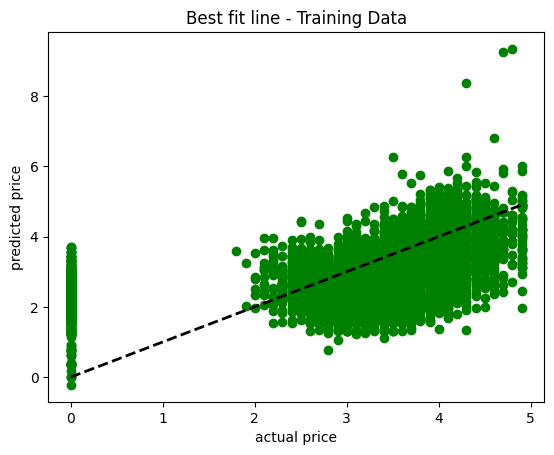

In [146]:
model_evaluation(y_train, x_train_pred)

In [171]:
def model_evaluation(actual, predicted) :
    mse =  mean_squared_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae =  mean_absolute_error(actual, predicted)
    r2 =   r2_score(actual, predicted)
    print(f'mse : {mse}')
    print(f'rmse : {rmse}')
    print(f'mae : {mae}')
    print(f'accuracy : {r2}')

    plt.scatter(actual, predicted, color='r')
    plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], color='k', ls='--', lw=2)
    plt.title('Best fit line - Training Data')
    plt.xlabel('actual price')
    plt.ylabel('predicted price')

mse : 1.5882557531726416
rmse : 1.2602601926477888
mae : 1.0486999397976529
accuracy : 0.30220575555273144


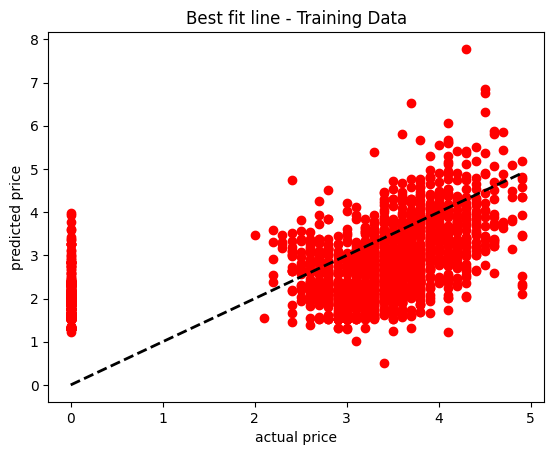

In [172]:
model_evaluation(y_test, x_test_pred)

In [151]:
model2 = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1)
model2.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [154]:
print(model2.score(x_train, y_train))
print(model2.score(x_test, y_test))

0.9860326632366981
0.954418346981449


In [155]:
x_train_pred_RF = model2.predict(x_train)
x_test_pred_RF = model2.predict(x_test)

In [161]:
y_train[:5]

1115    3.3
7633    3.0
8267    0.0
7209    0.0
6242    2.5
Name: aggregate_rating, dtype: float64

In [162]:
x_train_pred_RF[:5]

array([3.4123119 , 2.98809067, 0.        , 0.        , 3.02268333])

In [165]:
y_test[:5]

4731    2.1
1468    4.1
9037    3.2
7866    4.4
5570    3.5
Name: aggregate_rating, dtype: float64

In [166]:
x_test_pred_RF[:5]

array([3.25482996, 3.21510714, 3.17650493, 3.81644246, 3.01170913])

In [169]:
def model_evaluation(actual, predicted) :
    mse =  mean_squared_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae =  mean_absolute_error(actual, predicted)
    r2 =   r2_score(actual, predicted)
    print(f'mse : {mse}')
    print(f'rmse : {rmse}')
    print(f'mae : {mae}')
    print(f'accuracy : {r2}')

    plt.scatter(actual, predicted, color='y')
    plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], color='k', ls='--', lw=2)
    plt.title('Best fit line - Training Data')
    plt.xlabel('actual price')
    plt.ylabel('predicted price')

mse : 0.03219083182751373
rmse : 0.17941803651671626
mae : 0.11431669542264888
accuracy : 0.9860326632366981


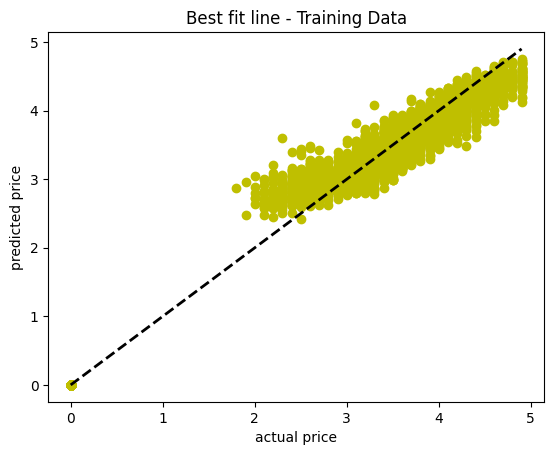

In [170]:
model_evaluation(y_train, x_train_pred_RF)

In [ ]:
def model_evaluation(actual, predicted) :
    mse =  mean_squared_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae =  mean_absolute_error(actual, predicted)
    r2 =   r2_score(actual, predicted)
    print(f'mse : {mse}')
    print(f'rmse : {rmse}')
    print(f'mae : {mae}')
    print(f'accuracy : {r2}')

    plt.scatter(actual, predicted, color='r')
    plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], color='k', ls='--', lw=2)
    plt.title('Best fit line - Training Data')
    plt.xlabel('actual price')
    plt.ylabel('predicted price')

mse : 0.10374881022869135
rmse : 0.3221006212795799
mae : 0.21039460905540192
accuracy : 0.954418346981449


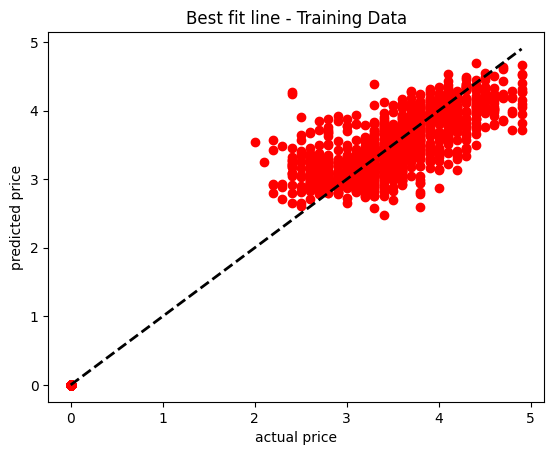

In [173]:
model_evaluation(y_test, x_test_pred_RF)

In [150]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1),
    'Extra Trees': ExtraTreesRegressor(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1)
}
results = []

for name, regressor in models.items():

    regressor.fit(x_train, y_train)

    predictions = regressor.predict(x_test)

    results.append({
        'Model': name,
        'R2 Score': r2_score(y_test, predictions),
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions))
    })
results_df = pd.DataFrame(results)
results_df.sort_values('R2 Score', ascending=False)

,Model,R2 Score,MAE,RMSE
2,Random Forest,0.954418,0.210395,0.322101
1,Decision Tree,0.948418,0.225100,0.342645
3,Extra Trees,0.945803,0.237454,0.351224
0,Linear Regression,0.302206,1.048700,1.260260
